In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

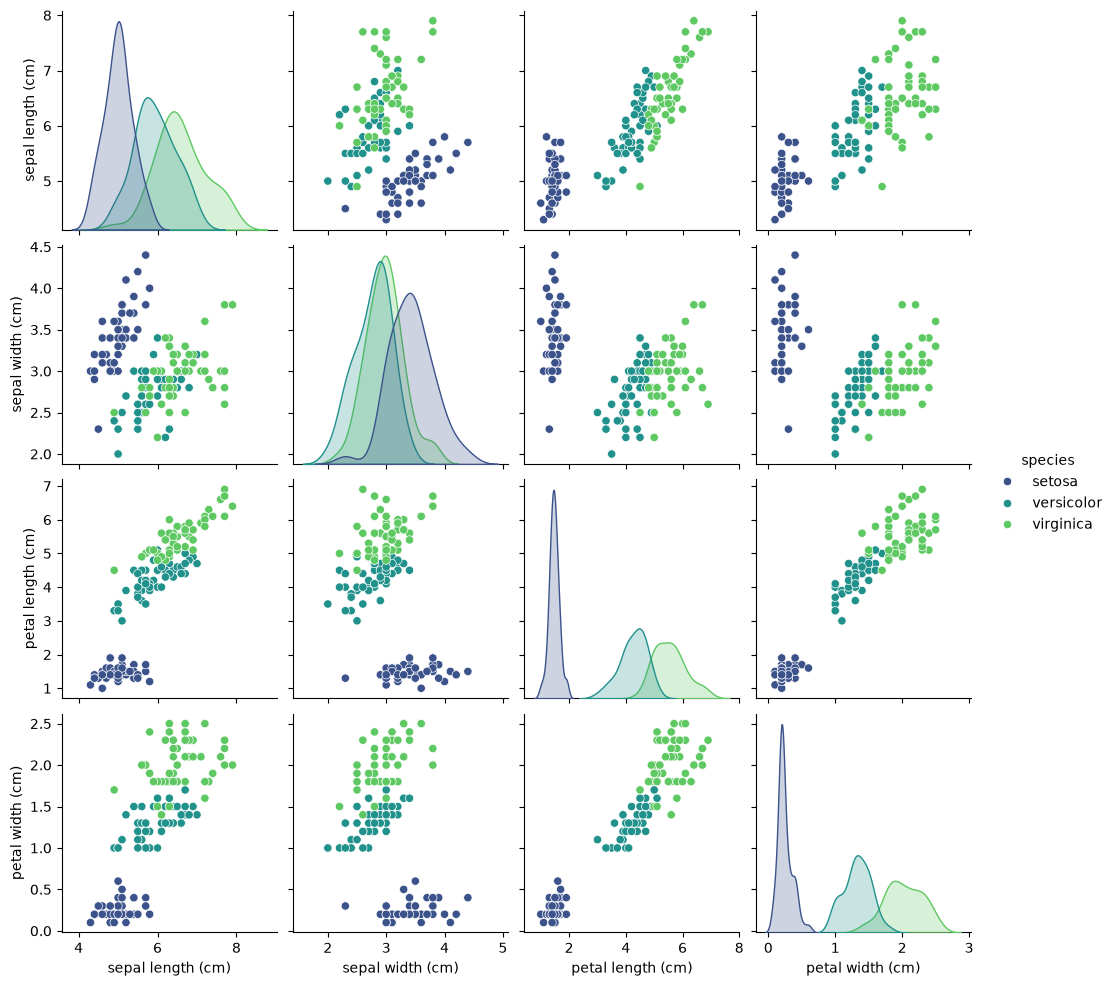

In [2]:
# Cargar datos de Iris
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['species'] = df['target'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})

# Gráfico de pares exploratorio con Seaborn
sns.pairplot(df.drop('target', axis=1), hue='species', palette='viridis')
plt.show()

In [3]:
# Variables independientes (X) y objetivo (y)
X = df.drop(['target', 'species'], axis=1)
y = df['target']

# División 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalizar con StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Datos divididos y normalizados con éxito.")

Datos divididos y normalizados con éxito.


In [4]:
# 1. Regresión Logística
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)

# 2. Árbol de Decisión
tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(X_train_scaled, y_train)

print("Modelos LogisticRegression y DecisionTreeClassifier entrenados.")

Modelos LogisticRegression y DecisionTreeClassifier entrenados.


--- MÉTRICAS REGRESIÓN LOGÍSTICA ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



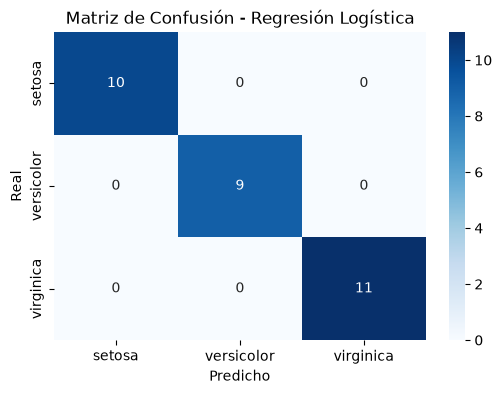

In [5]:
# Predicciones
preds_log = log_reg.predict(X_test_scaled)
preds_tree = tree_clf.predict(X_test_scaled)

# Reporte de métricas (Precisión, Exhaustividad, F1)
print("--- MÉTRICAS REGRESIÓN LOGÍSTICA ---")
print(classification_report(y_test, preds_log, target_names=iris.target_names))

# Matriz de Confusión para Regresión Logística
cm = confusion_matrix(y_test, preds_log)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='g', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title('Matriz de Confusión - Regresión Logística')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.show()

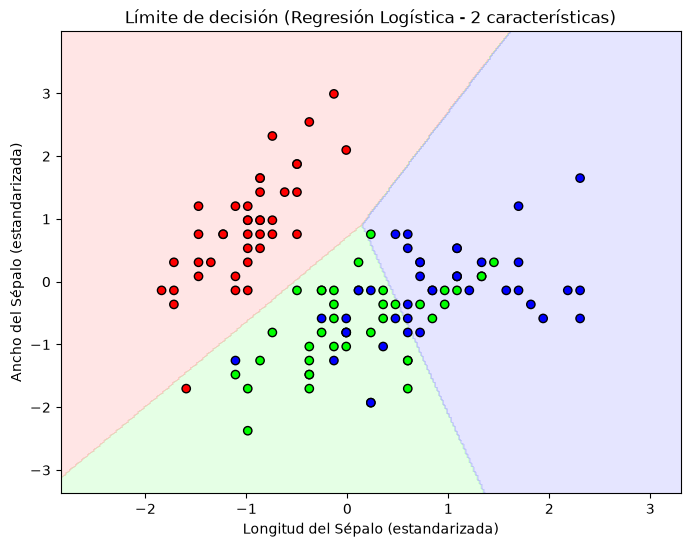

In [6]:
# Para graficar en 2D, entrenamos un modelo solo con las primeras 2 características
X_vis = X_train_scaled[:, :2]
log_reg_vis = LogisticRegression(random_state=42).fit(X_vis, y_train)

# Crear malla para el fondo
x_min, x_max = X_vis[:, 0].min() - 1, X_vis[:, 0].max() + 1
y_min, y_max = X_vis[:, 1].min() - 1, X_vis[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

# Predecir sobre la malla
Z = log_reg_vis.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

# Graficar
plt.figure(figsize=(8, 6))
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

plt.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_light)
plt.scatter(X_vis[:, 0], X_vis[:, 1], c=y_train, edgecolor='k', cmap=cmap_bold)
plt.title('Límite de decisión (Regresión Logística - 2 características)')
plt.xlabel('Longitud del Sépalo (estandarizada)')
plt.ylabel('Ancho del Sépalo (estandarizada)')
plt.show()